In [16]:

from pathlib import Path

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [17]:


# Set the dataset file path
DATA_PATH = Path(
    r"D:\Fraud Detection model project 2\Raw_dataset\financial_fraud_detection_feature_engineered.csv"
)

# Check whether the file exists
if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)

    print("Dataset loaded successfully!")
    print("File location:", DATA_PATH)
    print("Number of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])

    display(df.head())
else:
    print("ERROR: Dataset file not found!")
    print("Please check the folder and filename:")
    print(DATA_PATH)


Dataset loaded successfully!
File location: D:\Fraud Detection model project 2\Raw_dataset\financial_fraud_detection_feature_engineered.csv
Number of rows: 5000
Number of columns: 20


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Merchant_Category,Payment_Method,Device_Type,Location,Is_International,Previous_Transactions,Average_Spend,Account_Age_Days,Suspicious_Keyword,Fraudulent,Transaction_Hour,Day_of_Week,Transaction_Month,Is_Weekend,High_Amount,Is_Night
0,T100000,CUST3252,2023-10-04 07:45:00,37.54,Travel,PayPal,POS,Bengaluru,0,94,417.40,1492,No,0,7,2,10,0,0,0
1,T100001,CUST1630,2023-09-26 08:29:00,240.81,Utilities,PayPal,Mobile,Bengaluru,0,76,335.47,66,No,0,8,1,9,0,1,0
2,T100002,CUST7852,2023-07-18 15:54:00,105.34,Entertainment,Debit Card,Mobile,Bengaluru,0,60,432.03,216,No,0,15,1,7,0,0,0
3,T100003,CUST4892,2023-10-16 17:10:00,73.04,Utilities,NetBanking,Desktop,Kolkata,0,68,488.30,449,No,0,17,0,10,0,0,0
4,T100004,CUST8831,2023-09-09 00:46:00,13.57,Utilities,Credit Card,Desktop,Bengaluru,0,57,437.03,754,No,0,0,5,9,1,0,1


In [18]:
# Display all column names
print("Dataset columns:")
print(df.columns.tolist())

# Display dataset information
df.info()

# Check the first five rows
display(df.head())


Dataset columns:
['Transaction_ID', 'Customer_ID', 'Transaction_Date', 'Transaction_Amount', 'Merchant_Category', 'Payment_Method', 'Device_Type', 'Location', 'Is_International', 'Previous_Transactions', 'Average_Spend', 'Account_Age_Days', 'Suspicious_Keyword', 'Fraudulent', 'Transaction_Hour', 'Day_of_Week', 'Transaction_Month', 'Is_Weekend', 'High_Amount', 'Is_Night']
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Transaction_ID         5000 non-null   str    
 1   Customer_ID            5000 non-null   str    
 2   Transaction_Date       5000 non-null   str    
 3   Transaction_Amount     5000 non-null   float64
 4   Merchant_Category      5000 non-null   str    
 5   Payment_Method         5000 non-null   str    
 6   Device_Type            5000 non-null   str    
 7   Location               5000 non-null   str    
 8   Is_In

,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Merchant_Category,Payment_Method,Device_Type,Location,Is_International,Previous_Transactions,Average_Spend,Account_Age_Days,Suspicious_Keyword,Fraudulent,Transaction_Hour,Day_of_Week,Transaction_Month,Is_Weekend,High_Amount,Is_Night
0,T100000,CUST3252,2023-10-04 07:45:00,37.54,Travel,PayPal,POS,Bengaluru,0,94,417.40,1492,No,0,7,2,10,0,0,0
1,T100001,CUST1630,2023-09-26 08:29:00,240.81,Utilities,PayPal,Mobile,Bengaluru,0,76,335.47,66,No,0,8,1,9,0,1,0
2,T100002,CUST7852,2023-07-18 15:54:00,105.34,Entertainment,Debit Card,Mobile,Bengaluru,0,60,432.03,216,No,0,15,1,7,0,0,0
3,T100003,CUST4892,2023-10-16 17:10:00,73.04,Utilities,NetBanking,Desktop,Kolkata,0,68,488.30,449,No,0,17,0,10,0,0,0
4,T100004,CUST8831,2023-09-09 00:46:00,13.57,Utilities,Credit Card,Desktop,Bengaluru,0,57,437.03,754,No,0,0,5,9,1,0,1


In [19]:
# checking any fradulant 
if "Fraudulent" not in df.columns:
    raise ValueError("The 'Fraudulent' target column is missing!")

In [20]:
# checking missing values
print("\nMissing values in each column:")
print(df.isnull().sum())


Missing values in each column:
Transaction_ID           0
Customer_ID              0
Transaction_Date         0
Transaction_Amount       0
Merchant_Category        0
Payment_Method           0
Device_Type              0
Location                 0
Is_International         0
Previous_Transactions    0
Average_Spend            0
Account_Age_Days         0
Suspicious_Keyword       0
Fraudulent               0
Transaction_Hour         0
Day_of_Week              0
Transaction_Month        0
Is_Weekend               0
High_Amount              0
Is_Night                 0
dtype: int64


In [21]:
# check duplicate values
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [22]:
# Count fraudulent and legitimate transactions
print("\nFraudulent transaction distribution:")
print(df["Fraudulent"].value_counts())


Fraudulent transaction distribution:
Fraudulent
0    4518
1     482
Name: count, dtype: int64


In [23]:
# display class percentage
print("\nClass percentages:")
print((df["Fraudulent"].value_counts(normalize=True) * 100).round(2))



Class percentages:
Fraudulent
0    90.36
1     9.64
Name: proportion, dtype: float64


In [24]:

# Separate input features and target

# The column we want to predict
target_column = "Fraudulent"

# Columns that should not be used as model inputs
columns_to_drop = [
    "Fraudulent",
    "Transaction_ID",
    "Customer_ID",
    "Transaction_Date"
]

# Keep only columns that actually exist in the dataset
columns_to_drop = [
    col for col in columns_to_drop
    if col in df.columns
]

# X contains input features
X = df.drop(columns=columns_to_drop)

# y contains the correct answers
y = df[target_column].astype(int)

# Display the results
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())



Features shape: (5000, 16)
Target shape: (5000,)

Feature columns:
['Transaction_Amount', 'Merchant_Category', 'Payment_Method', 'Device_Type', 'Location', 'Is_International', 'Previous_Transactions', 'Average_Spend', 'Account_Age_Days', 'Suspicious_Keyword', 'Transaction_Hour', 'Day_of_Week', 'Transaction_Month', 'Is_Weekend', 'High_Amount', 'Is_Night']

Target distribution:
Fraudulent
0    4518
1     482
Name: count, dtype: int64


In [25]:

from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training features: (4000, 16)
Testing features: (1000, 16)

Training target distribution:
Fraudulent
0    3614
1     386
Name: count, dtype: int64

Testing target distribution:
Fraudulent
0    904
1     96
Name: count, dtype: int64


In [26]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numeric and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Preprocessing for numeric features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing pipeline created successfully!")


Numeric features: ['Transaction_Amount', 'Is_International', 'Previous_Transactions', 'Average_Spend', 'Account_Age_Days', 'Transaction_Hour', 'Day_of_Week', 'Transaction_Month', 'Is_Weekend', 'High_Amount', 'Is_Night']

Categorical features: ['Merchant_Category', 'Payment_Method', 'Device_Type', 'Location', 'Suspicious_Keyword']

Preprocessing pipeline created successfully!


C:\Users\umair\AppData\Local\Temp\ipykernel_16828\2684912681.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [27]:
# Logistic Regression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict transaction classes
y_pred = logistic_model.predict(X_test)

# Predict fraud probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("LOGISTIC REGRESSION - MODEL EVALUATION")
print("-" * 45)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


LOGISTIC REGRESSION - MODEL EVALUATION
---------------------------------------------
Accuracy:  0.7600
Precision: 0.2831
Recall:    0.9792
F1-Score:  0.4393
ROC-AUC:   0.8905

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.74      0.85       904
  Fraudulent       0.28      0.98      0.44        96

    accuracy                           0.76      1000
   macro avg       0.64      0.86      0.64      1000
weighted avg       0.93      0.76      0.81      1000

Confusion Matrix:
[[666 238]
 [  2  94]]


In [34]:
# Decision Tree model.

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42,
        max_depth=10
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [35]:
# Random Forest model.

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [36]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Store the trained models
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

# Compare model performance
results = []

for model_name, model in models.items():
    # Predict classes and fraud probabilities
    y_pred_model = model.predict(X_test)
    y_prob_model = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred_model),
        "Precision": precision_score(
            y_test, y_pred_model, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_model, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred_model, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob_model)
    })

# Display comparison table
comparison_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(
    comparison_df.sort_values(
        by="F1-Score", ascending=False
    ).round(4)
)


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
2,Random Forest,0.906,0.5135,0.3958,0.4471,0.8977
0,Logistic Regression,0.760,0.2831,0.9792,0.4393,0.8905
1,Decision Tree,0.774,0.2500,0.6771,0.3652,0.7494


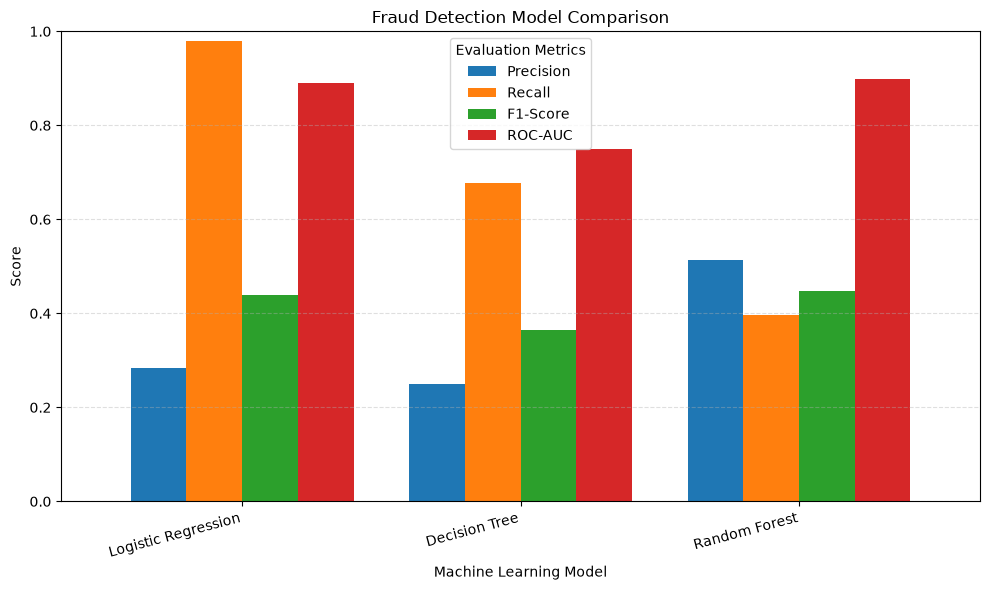

In [37]:

# import matplotlib.pyplot as plt

# Metrics to compare
metrics = ["Precision", "Recall", "F1-Score", "ROC-AUC"]

# Prepare the comparison chart
chart_data = comparison_df.set_index("Model")[metrics]

ax = chart_data.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Fraud Detection Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [38]:

# from pathlib import Path
# import joblib

# Create the models folder in the project directory
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Select the model with the highest F1-score
best_model_name = comparison_df.loc[
    comparison_df["F1-Score"].idxmax(), "Model"
]

best_model = models[best_model_name]

print("Selected model:", best_model_name)
print(
    "F1-score:",
    round(
        comparison_df.loc[
            comparison_df["Model"] == best_model_name,
            "F1-Score"
        ].iloc[0],
        4
    )
)

# Save the best model
joblib.dump(
    best_model,
    MODELS_DIR / "best_fraud_model.joblib"
)

# Save all three models
joblib.dump(
    models,
    MODELS_DIR / "all_fraud_models.joblib"
)

# Save the comparison report
comparison_df.to_csv(
    MODELS_DIR / "model_comparison.csv",
    index=False
)

print("\nFiles saved successfully:")
print(MODELS_DIR / "best_fraud_model.joblib")
print(MODELS_DIR / "all_fraud_models.joblib")
print(MODELS_DIR / "model_comparison.csv")


Selected model: Random Forest
F1-score: 0.4471

Files saved successfully:
d:\Fraud Detection model project 2\models\best_fraud_model.joblib
d:\Fraud Detection model project 2\models\all_fraud_models.joblib
d:\Fraud Detection model project 2\models\model_comparison.csv


Selected model: Random Forest

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.94      0.96      0.95       904
  Fraudulent       0.51      0.40      0.45        96

    accuracy                           0.91      1000
   macro avg       0.73      0.68      0.70      1000
weighted avg       0.90      0.91      0.90      1000



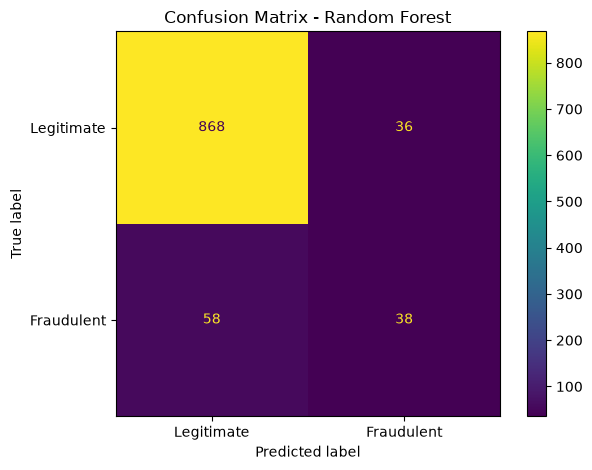

In [39]:

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt

# Predict using the selected best model
y_pred_best = best_model.predict(X_test)

# Display detailed evaluation
print("Selected model:", best_model_name)
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_best,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred_best)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraudulent"]
).plot(values_format="d")

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()
